In [1]:
!pip install -q git+https://github.com/abhibarnwal707/PaperTrail.git
import os
from kaggle_secrets import UserSecretsClient
os.environ["DAGSHUB_USER_TOKEN"] = UserSecretsClient().get_secret("DAGSHUB_TOKEN")
import dagshub, mlflow
dagshub.init(repo_owner="abhibarnwal707", repo_name="papertrail", mlflow=True)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 537.9 kB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.1 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 953.1 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.0/274.0 kB 2.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 49.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 67.9 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 45.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 kB 6.2 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.1 MB/s eta 0:00:00
   ━━

Accessing as abhibarnwal707

Initialized MLflow to track repo "abhibarnwal707/papertrail"

Repository abhibarnwal707/papertrail initialized!

In [2]:
mlflow.log_metric("smoke_test", 1)

In [3]:
import polars as pl
P = "/kaggle/input/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml/"
COLS = ["ts","from_bank","from_acct","to_bank","to_acct",
        "amt_recv","cur_recv","amt_paid","cur_paid","pay_format","label"]
df = (pl.read_csv(P+"HI-Small_Trans.csv", new_columns=COLS,
                  schema_overrides={"from_acct": pl.Utf8, "to_acct": pl.Utf8})
        .with_columns(
            pl.col("ts").str.strptime(pl.Datetime, "%Y/%m/%d %H:%M"),
            (pl.col("from_bank").cast(pl.Utf8)+"_"+pl.col("from_acct")).alias("src"),
            (pl.col("to_bank").cast(pl.Utf8)+"_"+pl.col("to_acct")).alias("dst"),
        )
        .sort("ts")
        .with_row_index("txn_id"))

In [5]:
df.head()

txn_id,ts,from_bank,from_acct,to_bank,to_acct,amt_recv,cur_recv,amt_paid,cur_paid,pay_format,label,src,dst
u32,datetime[μs],i64,str,i64,str,f64,str,f64,str,str,i64,str,str
0,2022-09-01 00:00:00,3209,"""8000F4670""",3209,"""8000F4670""",14675.57,"""US Dollar""",14675.57,"""US Dollar""","""Reinvestment""",0,"""3209_8000F4670""","""3209_8000F4670"""
1,2022-09-01 00:00:00,1420,"""8005DFEB0""",1420,"""8005DFEB0""",897.37,"""US Dollar""",897.37,"""US Dollar""","""Reinvestment""",0,"""1420_8005DFEB0""","""1420_8005DFEB0"""
2,2022-09-01 00:00:00,10,"""8000F6850""",10,"""8000F6850""",99986.94,"""US Dollar""",99986.94,"""US Dollar""","""Reinvestment""",0,"""10_8000F6850""","""10_8000F6850"""
3,2022-09-01 00:00:00,12,"""8001167D0""",12,"""8001167D0""",16.08,"""US Dollar""",16.08,"""US Dollar""","""Reinvestment""",0,"""12_8001167D0""","""12_8001167D0"""
4,2022-09-01 00:00:00,1,"""8001364A0""",1,"""8001364A0""",10.3,"""US Dollar""",10.3,"""US Dollar""","""Reinvestment""",0,"""1_8001364A0""","""1_8001364A0"""


5078345 5177 0.0010194266045335635
2022-09-01 00:00:00 2022-09-18 16:18:00
shape: (18, 4)
┌────────────┬─────────┬─────┬──────────┐
│ day        ┆ n       ┆ pos ┆ rate     │
│ ---        ┆ ---     ┆ --- ┆ ---      │
│ date       ┆ u32     ┆ i64 ┆ f64      │
╞════════════╪═════════╪═════╪══════════╡
│ 2022-09-01 ┆ 1114921 ┆ 322 ┆ 0.000289 │
│ 2022-09-02 ┆ 754449  ┆ 408 ┆ 0.000541 │
│ 2022-09-03 ┆ 207382  ┆ 391 ┆ 0.001885 │
│ 2022-09-04 ┆ 207430  ┆ 407 ┆ 0.001962 │
│ 2022-09-05 ┆ 482650  ┆ 471 ┆ 0.000976 │
│ …          ┆ …       ┆ …   ┆ …        │
│ 2022-09-14 ┆ 121     ┆ 70  ┆ 0.578512 │
│ 2022-09-15 ┆ 46      ┆ 28  ┆ 0.608696 │
│ 2022-09-16 ┆ 46      ┆ 26  ┆ 0.565217 │
│ 2022-09-17 ┆ 23      ┆ 15  ┆ 0.652174 │
│ 2022-09-18 ┆ 11      ┆ 8   ┆ 0.727273 │
└────────────┴─────────┴─────┴──────────┘


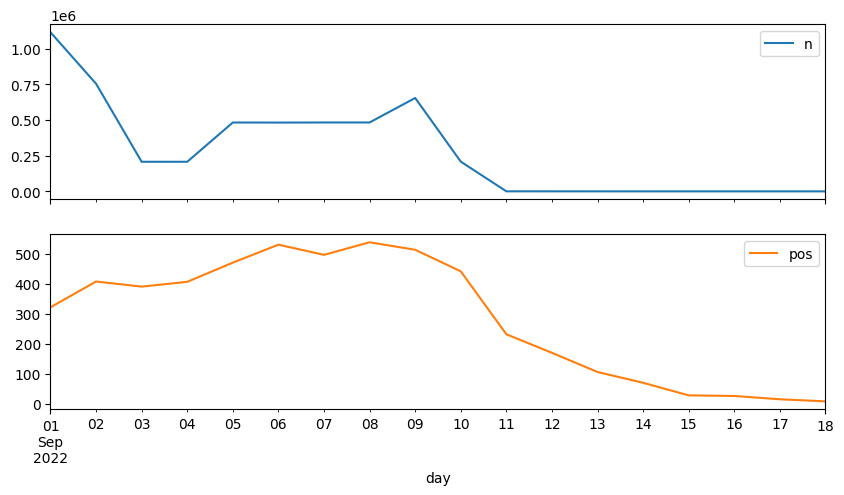

In [6]:
# Q1 and Q2: label rate and volume per day
daily = (df.group_by(pl.col("ts").dt.date().alias("day"))
           .agg(n=pl.len(), pos=pl.col("label").sum(), rate=pl.col("label").mean())
           .sort("day"))
print(df.height, df["label"].sum(), df["label"].mean())
print(df["ts"].min(), df["ts"].max())
print(daily)
daily.to_pandas().set_index("day")[["n","pos"]].plot(subplots=True, figsize=(10,5));
# Look for odd days at the start or end, such as very few transactions or a strange rate. We'll drop those in Phase 2.


In [7]:
# Q3: laundering rate by payment format and currency
for c in ["pay_format", "cur_paid"]:
    print(df.group_by(c)
            .agg(n=pl.len(), pos=pl.col("label").sum(), rate=pl.col("label").mean())
            .sort("rate", descending=True))

shape: (7, 4)
┌──────────────┬─────────┬──────┬──────────┐
│ pay_format   ┆ n       ┆ pos  ┆ rate     │
│ ---          ┆ ---     ┆ ---  ┆ ---      │
│ str          ┆ u32     ┆ i64  ┆ f64      │
╞══════════════╪═════════╪══════╪══════════╡
│ ACH          ┆ 600797  ┆ 4483 ┆ 0.007462 │
│ Bitcoin      ┆ 146091  ┆ 56   ┆ 0.000383 │
│ Cash         ┆ 490891  ┆ 108  ┆ 0.00022  │
│ Cheque       ┆ 1864331 ┆ 324  ┆ 0.000174 │
│ Credit Card  ┆ 1323324 ┆ 206  ┆ 0.000156 │
│ Wire         ┆ 171855  ┆ 0    ┆ 0.0      │
│ Reinvestment ┆ 481056  ┆ 0    ┆ 0.0      │
└──────────────┴─────────┴──────┴──────────┘
shape: (15, 4)
┌───────────────────┬─────────┬──────┬──────────┐
│ cur_paid          ┆ n       ┆ pos  ┆ rate     │
│ ---               ┆ ---     ┆ ---  ┆ ---      │
│ str               ┆ u32     ┆ i64  ┆ f64      │
╞═══════════════════╪═════════╪══════╪══════════╡
│ Saudi Riyal       ┆ 89014   ┆ 374  ┆ 0.004202 │
│ Euro              ┆ 1168297 ┆ 1372 ┆ 0.001174 │
│ US Dollar         ┆ 1895172 ┆ 1912

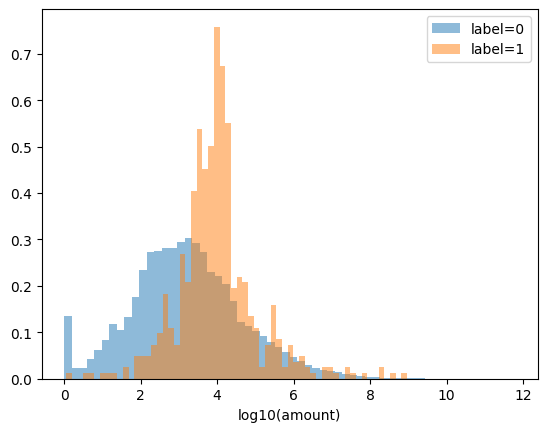

In [8]:
# %% Q4: amounts, laundering vs normal (log scale)
import numpy as np
import matplotlib.pyplot as plt
# %% Q4: amounts, laundering vs normal (log scale)
pdf = df.select("amt_paid", "label").sample(500_000, seed=0).to_pandas()
for lab, g in pdf.groupby("label"):
    plt.hist(np.log10(g["amt_paid"] + 1), bins=60, alpha=.5, density=True, label=f"label={lab}")
plt.xlabel("log10(amount)")
plt.legend()
plt.show()

In [9]:
# %% Q5: self-transfers and cross-currency
flags = df.with_columns(
    self_xfer=(pl.col("src") == pl.col("dst")),
    cross_cur=(pl.col("cur_paid") != pl.col("cur_recv")))
for c in ["self_xfer", "cross_cur"]:
    print(flags.group_by(c).agg(n=pl.len(), rate=pl.col("label").mean()))

shape: (2, 3)
┌───────────┬─────────┬──────────┐
│ self_xfer ┆ n       ┆ rate     │
│ ---       ┆ ---     ┆ ---      │
│ bool      ┆ u32     ┆ f64      │
╞═══════════╪═════════╪══════════╡
│ true      ┆ 591212  ┆ 0.000019 │
│ false     ┆ 4487133 ┆ 0.001151 │
└───────────┴─────────┴──────────┘
shape: (2, 3)
┌───────────┬─────────┬──────────┐
│ cross_cur ┆ n       ┆ rate     │
│ ---       ┆ ---     ┆ ---      │
│ bool      ┆ u32     ┆ f64      │
╞═══════════╪═════════╪══════════╡
│ false     ┆ 5006175 ┆ 0.001034 │
│ true      ┆ 72170   ┆ 0.0      │
└───────────┴─────────┴──────────┘


In [10]:
# %% Q6: hour of day and weekday
t = df.with_columns(hour=pl.col("ts").dt.hour(), wd=pl.col("ts").dt.weekday())
for c in ["hour", "wd"]:
    print(t.group_by(c).agg(n=pl.len(), rate=pl.col("label").mean()).sort(c))

shape: (24, 3)
┌──────┬────────┬──────────┐
│ hour ┆ n      ┆ rate     │
│ ---  ┆ ---    ┆ ---      │
│ i8   ┆ u32    ┆ f64      │
╞══════╪════════╪══════════╡
│ 0    ┆ 634726 ┆ 0.000277 │
│ 1    ┆ 193728 ┆ 0.000785 │
│ 2    ┆ 193143 ┆ 0.000854 │
│ 3    ┆ 193249 ┆ 0.000756 │
│ 4    ┆ 193166 ┆ 0.000797 │
│ …    ┆ …      ┆ …        │
│ 19   ┆ 192824 ┆ 0.001198 │
│ 20   ┆ 192809 ┆ 0.000695 │
│ 21   ┆ 192192 ┆ 0.000801 │
│ 22   ┆ 191836 ┆ 0.000667 │
│ 23   ┆ 193345 ┆ 0.000776 │
└──────┴────────┴──────────┘
shape: (7, 3)
┌─────┬─────────┬──────────┐
│ wd  ┆ n       ┆ rate     │
│ --- ┆ ---     ┆ ---      │
│ i8  ┆ u32     ┆ f64      │
╞═════╪═════════╪══════════╡
│ 1   ┆ 482931  ┆ 0.001327 │
│ 2   ┆ 482273  ┆ 0.001321 │
│ 3   ┆ 482872  ┆ 0.001174 │
│ 4   ┆ 1597740 ┆ 0.000556 │
│ 5   ┆ 1408962 ┆ 0.000673 │
│ 6   ┆ 415730  ┆ 0.00204  │
│ 7   ┆ 207837  ┆ 0.003113 │
└─────┴─────────┴──────────┘


shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 515088.0   │
│ null_count ┆ 0.0        │
│ mean       ┆ 19.718359  │
│ std        ┆ 287.508951 │
│ min        ┆ 1.0        │
│ 25%        ┆ 2.0        │
│ 50%        ┆ 6.0        │
│ 75%        ┆ 27.0       │
│ max        ┆ 169756.0   │
└────────────┴────────────┘
top 1% degree cutoff: 119.0


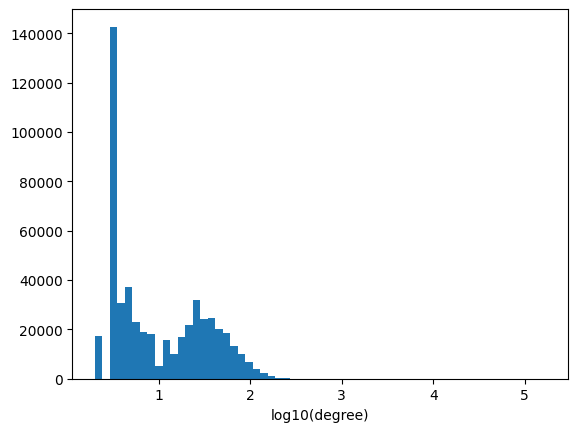

In [11]:
# %% Q7: degree distribution and hubs
outd = df.group_by("src").agg(out=pl.len()).rename({"src": "acct"})
ind = df.group_by("dst").agg(inn=pl.len()).rename({"dst": "acct"})
deg = (outd.join(ind, on="acct", how="full", coalesce=True)
           .fill_null(0)
           .with_columns(deg=pl.col("out") + pl.col("inn")))
print(deg["deg"].describe())
print("top 1% degree cutoff:", deg["deg"].quantile(0.99))
plt.hist(np.log10(deg["deg"].to_numpy() + 1), bins=60)
plt.xlabel("log10(degree)")
plt.show()

In [12]:
# save the full daily table (the earlier output was truncated)
pl.Config.set_tbl_rows(-1)
print(daily)
daily.write_csv("/kaggle/working/daily.csv")

# parse HI-Small_Patterns.txt into a table
rows, attempt, typ = [], -1, None
with open(P + "HI-Small_Patterns.txt") as fh:
    for line in fh:
        line = line.strip()
        if line.startswith("BEGIN"):
            attempt += 1
            typ = line.split(" - ")[1].split(":")[0].strip()
        elif line and not line.startswith("END"):
            f = line.split(",")
            # bank IDs have leading zeros here but not in the CSV, so normalise with int()
            rows.append((attempt, typ, f[0], f"{int(f[1])}_{f[2]}", f"{int(f[3])}_{f[4]}", float(f[7])))

patterns = (pl.DataFrame(rows, schema=["attempt_id", "typology", "ts", "src", "dst", "amt_paid"], orient="row")
              .with_columns(pl.col("ts").str.strptime(pl.Datetime, "%Y/%m/%d %H:%M")))

print("pattern rows:", patterns.height, "| attempts:", patterns["attempt_id"].n_unique())
print(patterns.group_by("typology").agg(rows=pl.len(), attempts=pl.col("attempt_id").n_unique())
              .sort("rows", descending=True))
print(patterns.head())


shape: (18, 4)
┌────────────┬─────────┬─────┬──────────┐
│ day        ┆ n       ┆ pos ┆ rate     │
│ ---        ┆ ---     ┆ --- ┆ ---      │
│ date       ┆ u32     ┆ i64 ┆ f64      │
╞════════════╪═════════╪═════╪══════════╡
│ 2022-09-01 ┆ 1114921 ┆ 322 ┆ 0.000289 │
│ 2022-09-02 ┆ 754449  ┆ 408 ┆ 0.000541 │
│ 2022-09-03 ┆ 207382  ┆ 391 ┆ 0.001885 │
│ 2022-09-04 ┆ 207430  ┆ 407 ┆ 0.001962 │
│ 2022-09-05 ┆ 482650  ┆ 471 ┆ 0.000976 │
│ 2022-09-06 ┆ 482089  ┆ 531 ┆ 0.001101 │
│ 2022-09-07 ┆ 482751  ┆ 497 ┆ 0.00103  │
│ 2022-09-08 ┆ 482773  ┆ 539 ┆ 0.001116 │
│ 2022-09-09 ┆ 654467  ┆ 514 ┆ 0.000785 │
│ 2022-09-10 ┆ 208325  ┆ 442 ┆ 0.002122 │
│ 2022-09-11 ┆ 396     ┆ 232 ┆ 0.585859 │
│ 2022-09-12 ┆ 281     ┆ 170 ┆ 0.604982 │
│ 2022-09-13 ┆ 184     ┆ 106 ┆ 0.576087 │
│ 2022-09-14 ┆ 121     ┆ 70  ┆ 0.578512 │
│ 2022-09-15 ┆ 46      ┆ 28  ┆ 0.608696 │
│ 2022-09-16 ┆ 46      ┆ 26  ┆ 0.565217 │
│ 2022-09-17 ┆ 23      ┆ 15  ┆ 0.652174 │
│ 2022-09-18 ┆ 11      ┆ 8   ┆ 0.727273 │
└────────────┴─────

In [13]:
# join typology onto the transactions
key = ["ts", "src", "dst", "amt_paid"]
# a key can repeat (identical rows, or one transaction in two attempts): keep the first
p1 = patterns.unique(subset=key, keep="first", maintain_order=True).select(key + ["attempt_id", "typology"])
print("duplicate keys dropped from patterns:", patterns.height - p1.height)

txn = (df.join(p1, on=key, how="left")
         .with_columns(
             # only laundering rows may carry a typology
             pl.when(pl.col("label") == 1).then(pl.col("typology")).alias("typology"),
             pl.when(pl.col("label") == 1).then(pl.col("attempt_id")).alias("attempt_id"))
         .sort("txn_id"))
assert txn.height == df.height, "join changed the row count"

# pattern rows that found no transaction at all (should be ~0)
missing = p1.join(df.select(key), on=key, how="anti")
print("pattern rows with no matching transaction:", missing.height)


duplicate keys dropped from patterns: 0
pattern rows with no matching transaction: 0


In [14]:
# %% Step 1.3c: the numbers you need to write down
pos = txn.filter(pl.col("label") == 1)
n_pos = pos.height
n_matched = pos["typology"].is_not_null().sum()
print(f"positives: {n_pos} | mapped to a typology: {n_matched} ({n_matched / n_pos:.1%}) | unmapped: {n_pos - n_matched}")

typ_counts = (pos.group_by("typology")
                 .agg(n=pl.len(),
                      share=pl.len() / n_pos,
                      ach_share=(pl.col("pay_format") == "ACH").mean())
                 .sort("n", descending=True))
print(typ_counts)
typ_counts.write_csv("/kaggle/working/typology_counts.csv")

# tail check: do the Sep 11+ positives belong to attempts that started earlier?
from datetime import datetime
TAIL = datetime(2022, 9, 11)
bounds = patterns.group_by("attempt_id").agg(start=pl.col("ts").min(), end=pl.col("ts").max())
tail_pos = pos.filter(pl.col("ts") >= TAIL)
chk = tail_pos.join(bounds, on="attempt_id", how="left")
print("tail positives:", tail_pos.height)
print("  started before Sep 11:", chk.filter(pl.col("start") < TAIL).height)
print("  started on/after Sep 11:", chk.filter(pl.col("start") >= TAIL).height)
print("  unmapped:", chk.filter(pl.col("start").is_null()).height)
print("attempt length (hours), summary:")
print(bounds.with_columns(hours=(pl.col("end") - pl.col("start")).dt.total_hours())["hours"].describe())


positives: 5177 | mapped to a typology: 3209 (62.0%) | unmapped: 1968
shape: (9, 4)
┌────────────────┬──────┬──────────┬───────────┐
│ typology       ┆ n    ┆ share    ┆ ach_share │
│ ---            ┆ ---  ┆ ---      ┆ ---       │
│ str            ┆ u32  ┆ f64      ┆ f64       │
╞════════════════╪══════╪══════════╪═══════════╡
│ null           ┆ 1968 ┆ 0.380143 ┆ 0.647866  │
│ GATHER-SCATTER ┆ 716  ┆ 0.138304 ┆ 1.0       │
│ SCATTER-GATHER ┆ 626  ┆ 0.120919 ┆ 1.0       │
│ STACK          ┆ 466  ┆ 0.090014 ┆ 0.997854  │
│ FAN-OUT        ┆ 342  ┆ 0.066061 ┆ 1.0       │
│ FAN-IN         ┆ 318  ┆ 0.061426 ┆ 1.0       │
│ CYCLE          ┆ 287  ┆ 0.055438 ┆ 1.0       │
│ BIPARTITE      ┆ 263  ┆ 0.050802 ┆ 1.0       │
│ RANDOM         ┆ 191  ┆ 0.036894 ┆ 1.0       │
└────────────────┴──────┴──────────┴───────────┘
tail positives: 655
  started before Sep 11: 645
  started on/after Sep 11: 10
  unmapped: 0
attempt length (hours), summary:
shape: (9, 2)
┌────────────┬───────────┐
│ statistic  ┆

In [15]:
# %% Step 1.4: save the processed data to /kaggle/working
txn.write_parquet("/kaggle/working/transactions.parquet")
patterns.write_parquet("/kaggle/working/patterns.parquet")

# quick check that they load fast
import time
t0 = time.time()
chk_t = pl.read_parquet("/kaggle/working/transactions.parquet")
chk_p = pl.read_parquet("/kaggle/working/patterns.parquet")
print(chk_t.shape, chk_p.shape, f"{time.time() - t0:.1f}s")
print(chk_t.columns)
!ls -lh /kaggle/working


(5078345, 16) (3209, 6) 0.7s
['txn_id', 'ts', 'from_bank', 'from_acct', 'to_bank', 'to_acct', 'amt_recv', 'cur_recv', 'amt_paid', 'cur_paid', 'pay_format', 'label', 'src', 'dst', 'attempt_id', 'typology']
total 161M
-rw-r--r-- 1 root root  747 Oct 19 05:11 daily.csv
-rw-r--r-- 1 root root  70K Oct 19 05:11 patterns.parquet
-rw-r--r-- 1 root root 161M Oct 19 05:11 transactions.parquet
-rw-r--r-- 1 root root  384 Oct 19 05:11 typology_counts.csv
